# TEMA 2 IA

In [7]:
import os

datasets_dir = 'datasets'
os.makedirs(datasets_dir, exist_ok=True)
print(f"Directory '{datasets_dir}' created or already exists.")

Directory 'datasets' created or already exists.


In [8]:
!unzip -oq /content/you-re-on-candid-camera.zip -d {datasets_dir}/you-re-on-candid-camera
!unzip -oq /content/vai-de-pielea-mea.zip -d {datasets_dir}/vai-de-pielea-mea

print("Extraction complete!")

Extraction complete!


In [9]:
import os
import pandas as pd
from PIL import Image
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision import transforms
import matplotlib.pyplot as plt
from torch.utils.tensorboard import SummaryWriter
from datetime import datetime
from contextlib import nullcontext
from sklearn.metrics import (
	accuracy_score,
	f1_score,
	confusion_matrix,
	ConfusionMatrixDisplay
)
import torch.nn.functional as F
import numpy as np
from torch.utils.data import WeightedRandomSampler
# --- Importuri Noi pentru Fine-Tuning ---
import copy
import time
import torchvision.transforms as T
from torchvision import models
from torch.utils.data import DataLoader, WeightedRandomSampler
from sklearn.metrics import f1_score, accuracy_score, classification_report, confusion_matrix
from torch.optim.lr_scheduler import LambdaLR, CosineAnnealingLR, SequentialLR
try:
    from tqdm.notebook import tqdm
except ImportError:
    from tqdm import tqdm

In [10]:
# --- DATASET BRUT PENTRU ALUNIȚE ---
class SkinLesionDatasetBrut(Dataset):
	def __init__(self, csv_file, img_dir, transform=None):
		self.annotations = pd.read_csv(csv_file)
		self.img_dir = img_dir
		self.transform = transform
		if 'diagnostic' in self.annotations.columns:
			unique_classes = sorted(self.annotations['diagnostic'].unique())
			self.class_to_idx = {cls_name: i for i, cls_name in enumerate(unique_classes)}

	def __len__(self):
		return len(self.annotations)

	def __getitem__(self, idx):
		img_name = self.annotations.iloc[idx, 0]
		if not img_name.endswith('.jpg'):
			img_name = f"{img_name}.jpg"
		img_path = os.path.join(self.img_dir, img_name)
		image = Image.open(img_path).convert("RGB")

		label_name = self.annotations.iloc[idx, 1]
		label = self.class_to_idx[label_name]

		if self.transform:
			image = self.transform(image)
		return image, label

# --- DATASET BRUT PENTRU EXPRESII FACIALE ---
class FacialExpressionDatasetBrut(Dataset):
	def __init__(self, csv_file, img_dir, transform=None):
		self.annotations = pd.read_csv(csv_file)
		self.img_dir = img_dir
		self.transform = transform

	def __len__(self):
		return len(self.annotations)

	def __getitem__(self, idx):
		img_relative_path = self.annotations.iloc[idx, 0]
		label = int(self.annotations.iloc[idx, 1]) - 1

		img_path = os.path.join(self.img_dir, img_relative_path)
		image = Image.open(img_path).convert("RGB")

		if self.transform:
			image = self.transform(image)
		return image, label

In [11]:
IMG_SIZE = 96
BATCH_SIZE = 64
# DATASET_NAME = "datasets/stanislavalex334ca/date-ia-tema2"

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
AMP_DTYPE = torch.float16 if DEVICE.type == "cuda" else torch.float32
NUM_WORKERS = min(4, os.cpu_count() or 1)
PIN_MEMORY = DEVICE.type == "cuda"
PERSISTENT_WORKERS = NUM_WORKERS > 0

if DEVICE.type == "cuda":
    torch.backends.cudnn.benchmark = True


def make_dataloader(dataset, batch_size, shuffle=False, sampler=None, drop_last=False, num_workers=NUM_WORKERS):
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle if sampler is None else False,
        sampler=sampler,
        drop_last=drop_last,
        num_workers=num_workers,
        pin_memory=PIN_MEMORY,
        persistent_workers=PERSISTENT_WORKERS if num_workers > 0 else False,
    )


norm_fete = {
    "mean": [0.5752126091262171, 0.4497227663589234, 0.4012869135370431],
    "std": [0.26532880449272844, 0.24229550144470252, 0.24068486736909714]
}

norm_alunite = {
    "mean": [0.7646, 0.5464, 0.5712],
    "std": [0.1410, 0.1532, 0.1706]
}

facial_basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_fete["mean"], std=norm_fete["std"])
])

medical_basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=norm_alunite["mean"], std=norm_alunite["std"])
])

# No augmentation
facial_train_no_aug_dataset = FacialExpressionDatasetBrut(
    csv_file=f"{datasets_dir}/you-re-on-candid-camera/splits/train.csv",
    img_dir=f"{datasets_dir}/you-re-on-candid-camera",
    transform=facial_basic_transform
)
facial_val_no_aug_dataset = FacialExpressionDatasetBrut(
    csv_file=f"{datasets_dir}/you-re-on-candid-camera/splits/local_test.csv",
    img_dir=f"{datasets_dir}/you-re-on-candid-camera",
    transform=facial_basic_transform
)

medical_train_no_aug_dataset = SkinLesionDatasetBrut(
    csv_file=f"{datasets_dir}/vai-de-pielea-mea/train.csv",
    img_dir=f"{datasets_dir}/vai-de-pielea-mea/train",
    transform=medical_basic_transform
)
medical_val_no_aug_dataset = SkinLesionDatasetBrut(
    csv_file=f"{datasets_dir}/vai-de-pielea-mea/test.csv",
    img_dir=f"{datasets_dir}/vai-de-pielea-mea/test",
    transform=medical_basic_transform
)

facial_train_no_aug_loader = make_dataloader(facial_train_no_aug_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
facial_val_no_aug_loader = make_dataloader(facial_val_no_aug_dataset, batch_size=BATCH_SIZE, shuffle=False)

medical_train_no_aug_loader = make_dataloader(medical_train_no_aug_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=True)
medical_val_no_aug_loader = make_dataloader(medical_val_no_aug_dataset, batch_size=BATCH_SIZE, shuffle=False)

print(f"Sistemul de incarcare a imaginilor este gata! device={DEVICE}, num_workers={NUM_WORKERS}, amp={USE_AMP}")


Sistemul de încărcare a imaginilor simple și brute este gata!


## DATASET

In [12]:
datasets = {
	"facial_no_aug": (
		facial_train_no_aug_loader,
		facial_val_no_aug_loader
	),

	"medical_no_aug": (
		medical_train_no_aug_loader,
		medical_val_no_aug_loader
	),
}

## PREZENTARE DIFERENTE IMAGINI FARA/CU AUGMENTARE

In [13]:
def arata_exemple_augmentare(loader_no_aug, loader_aug, num_classes=7, titlu="Set de date", seed=42):
    ds_no_aug = loader_no_aug.dataset
    ds_aug = loader_aug.dataset

    # If the augmented loader is a concat of [original, augmented], preview the augmented half.
    if hasattr(ds_aug, 'datasets') and len(ds_aug.datasets) >= 2:
        ds_aug_preview = ds_aug.datasets[1]
    else:
        ds_aug_preview = ds_aug

    gasite = {}

    for i in range(len(ds_no_aug)):
        _, label = ds_no_aug[i]

        if torch.is_tensor(label):
            label = label.item()

        if label not in gasite:
            gasite[label] = i
        if len(gasite) == num_classes:
            break

    clase = sorted(gasite.keys())
    fig, axes = plt.subplots(num_classes, 2, figsize=(8, 3 * num_classes))
    fig.suptitle(f"{titlu} - Inainte si Dupa Augmentare", fontsize=16, y=1.02)

    rng_state = torch.random.get_rng_state()
    torch.manual_seed(seed)

    for row_idx, cls in enumerate(clase):
        img_idx = gasite[cls]
        img_no_aug, _ = ds_no_aug[img_idx]
        img_aug, _ = ds_aug_preview[img_idx]

        def to_plot(tensor_img):
            tensor_img = tensor_img.detach().cpu().permute(1, 2, 0).numpy()
            tensor_img = (tensor_img - tensor_img.min()) / (tensor_img.max() - tensor_img.min() + 1e-5)
            return tensor_img

        ax_no_aug = axes[row_idx, 0]
        ax_aug = axes[row_idx, 1]

        ax_no_aug.imshow(to_plot(img_no_aug))
        ax_no_aug.set_title(f"Clasa {cls} - Original")
        ax_no_aug.axis('off')

        ax_aug.imshow(to_plot(img_aug))
        ax_aug.set_title(f"Clasa {cls} - Augmentat")
        ax_aug.axis('off')

    torch.random.set_rng_state(rng_state)
    plt.tight_layout()
    plt.show()


## Evaluare si antrenare

In [14]:
def train_one_epoch(model, loader, criterion, optimizer, device):
	model.train()
	running_loss = 0.0
	all_preds = []
	all_labels = []
	use_amp = device.type == "cuda"
	scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

	for images, labels in loader:
		images = images.to(device, non_blocking=True)
		labels = labels.to(device, non_blocking=True)

		optimizer.zero_grad(set_to_none=True)
		with torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=use_amp):
			logits = model(images)
			loss = criterion(logits, labels)

		scaler.scale(loss).backward()
		scaler.step(optimizer)
		scaler.update()

		running_loss += loss.item() * images.size(0)
		preds = logits.argmax(dim=1)

		all_preds.extend(preds.detach().cpu().numpy())
		all_labels.extend(labels.detach().cpu().numpy())

	epoch_loss = running_loss / len(loader.dataset)
	epoch_acc = accuracy_score(all_labels, all_preds)
	epoch_f1_macro = f1_score(all_labels, all_preds, average="macro")
	epoch_f1_micro = f1_score(all_labels, all_preds, average="micro")

	return epoch_loss, epoch_acc, epoch_f1_macro, epoch_f1_micro


In [15]:
@torch.no_grad()
def evaluate(model, loader, criterion, device):
	model.eval()
	running_loss = 0.0
	all_preds = []
	all_labels = []
	use_amp = device.type == "cuda"

	for images, labels in loader:
		images = images.to(device, non_blocking=True)
		labels = labels.to(device, non_blocking=True)

		with torch.autocast(device_type=device.type, dtype=AMP_DTYPE, enabled=use_amp):
			logits = model(images)
			loss = criterion(logits, labels)

		running_loss += loss.item() * images.size(0)
		preds = logits.argmax(dim=1)

		all_preds.extend(preds.detach().cpu().numpy())
		all_labels.extend(labels.detach().cpu().numpy())

	epoch_loss = running_loss / len(loader.dataset)
	epoch_acc = accuracy_score(all_labels, all_preds)
	epoch_f1_macro = f1_score(all_labels, all_preds, average="macro")
	epoch_f1_micro = f1_score(all_labels, all_preds, average="micro")

	return epoch_loss, epoch_acc, epoch_f1_macro, epoch_f1_micro, all_labels, all_preds


In [16]:
def ruleaza_pipeline_complet(model, train_loader, val_loader, model_name,
                             criterion=None, optimizer=None, scheduler=None,
                             lr=1e-3, num_epochs=20, weight_decay=1e-4):

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)

    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    if optimizer is None:
        optimizer = optim.Adam(
            model.parameters(),
            lr=lr,
            weight_decay=weight_decay
        )

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")

    run_name = f"{model_name}_lr_{lr}_{timestamp}"

    writer = SummaryWriter(log_dir=f"runs/{run_name}")

    history = {
        "train_loss": [],
        "train_acc": [],
        "train_f1_macro": [],
        "train_f1_micro": [],
        "val_loss": [],
        "val_acc": [],
        "val_f1_macro": [],
        "val_f1_micro": []
    }

    for epoch in range(num_epochs):

        tr_loss, tr_acc, tr_f1_macro, tr_f1_micro = train_one_epoch(
            model, train_loader, criterion, optimizer, device
        )

        va_loss, va_acc, va_f1_macro, va_f1_micro, _, _ = evaluate(
            model, val_loader, criterion, device
        )

        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["train_f1_macro"].append(tr_f1_macro)
        history["train_f1_micro"].append(tr_f1_micro)

        history["val_loss"].append(va_loss)
        history["val_acc"].append(va_acc)
        history["val_f1_macro"].append(va_f1_macro)
        history["val_f1_micro"].append(va_f1_micro)

        writer.add_scalar("Loss/train", tr_loss, epoch)
        writer.add_scalar("Loss/val", va_loss, epoch)

        writer.add_scalar("Accuracy/train", tr_acc, epoch)
        writer.add_scalar("Accuracy/val", va_acc, epoch)

        writer.add_scalar("F1_macro/train", tr_f1_macro, epoch)
        writer.add_scalar("F1_macro/val", va_f1_macro, epoch)

        writer.add_scalar("F1_micro/train", tr_f1_micro, epoch)
        writer.add_scalar("F1_micro/val", va_f1_micro, epoch)

        writer.add_scalar("LR", optimizer.param_groups[0]["lr"], epoch)

        print(f"[{model_name}] Epoca {epoch+1:02d} | "
              f"train loss={tr_loss:.4f} acc={tr_acc:.3f} "
              f"f1_macro={tr_f1_macro:.3f} f1_micro={tr_f1_micro:.3f} | "
              f"val loss={va_loss:.4f} acc={va_acc:.3f} "
              f"f1_macro={va_f1_macro:.3f} f1_micro={va_f1_micro:.3f}")

        if scheduler is not None:
            scheduler.step()

    writer.close()

    return history

In [39]:
def afiseaza_rezultate_finale(model, history, val_loader, model_name, class_names=None):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = model.to(device)
    model.eval()

    all_preds = []
    all_labels = []
    best_val_f1_macro = max(history["val_f1_macro"])

    # Fix: Creăm folderul 'models' dacă nu există și folosim o cale relativă
    os.makedirs("models", exist_ok=True)
    save_path = f"models/best_{model_name.lower()}.pt"

    torch.save(model.state_dict(), save_path)
    print(f"Model salvat: {save_path}")

    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            logits = model(images)
            preds = logits.argmax(dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], label="train loss")
    axes[0].plot(history["val_loss"], label="validation loss")
    axes[0].set_title(f"Loss - {model_name}")
    axes[0].legend()

    axes[1].plot(history["train_acc"], label="train accuracy")
    axes[1].plot(history["val_acc"], label="validation accuracy")
    axes[1].set_title(f"Accuracy - {model_name}")
    axes[1].legend()
    plt.tight_layout()
    plt.show()

    cm = confusion_matrix(all_labels, all_preds)
    fig, ax = plt.subplots(figsize=(8, 8))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
    disp.plot(cmap="Blues", ax=ax, xticks_rotation=45)
    plt.title(f"Confusion Matrix - {model_name}")
    plt.tight_layout()
    plt.show()

    print(f"Best validation f1_macro: {best_val_f1_macro:.4f}")

## CRITERII DE DEZECHILIBRU

In [18]:
def get_weighted_cross_entropy(labels, device):
    labels = np.array(labels)

    class_counts = np.bincount(labels)

    counts = torch.tensor(class_counts, dtype=torch.float)

    weights = counts.sum() / (len(counts) * counts)

    weights = weights.to(device)

    criterion = nn.CrossEntropyLoss(weight=weights)

    return criterion

def get_weighted_sampler(labels):
    labels = np.array(labels)

    class_counts = np.bincount(labels)

    class_weights = 1.0 / class_counts

    sample_weights = class_weights[labels]

    sampler = WeightedRandomSampler(
        weights=torch.DoubleTensor(sample_weights),
        num_samples=len(sample_weights),
        replacement=True
    )

    return sampler

class FocalLoss(nn.Module):
    def __init__(self,
                 alpha=None,
                 gamma=2.0,
                 reduction="mean"):

        super().__init__()

        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, logits, targets):

        ce = F.cross_entropy(
            logits,
            targets,
            weight=self.alpha,
            reduction="none"
        )

        p_t = torch.exp(-ce)

        loss = ((1 - p_t) ** self.gamma) * ce

        if self.reduction == "mean":
            return loss.mean()

        elif self.reduction == "sum":
            return loss.sum()

        return loss

def get_focal_loss(labels,
                   device,
                   gamma=2.0):
    labels = np.array(labels)

    class_counts = np.bincount(labels)

    counts = torch.tensor(class_counts, dtype=torch.float)

    weights = counts.sum() / (len(counts) * counts)

    weights = weights.to(device)

    return FocalLoss(
        alpha=weights,
        gamma=gamma
    )

## MLP Simplu

In [19]:
class SimpleMLP(nn.Module):
	def __init__(self, num_classes, img_size):
		super().__init__()

		self.net = nn.Sequential(
			nn.Flatten(),
			nn.Linear(3 * img_size * img_size, 512),
			nn.ReLU(inplace=True),
			nn.Linear(512, num_classes)
		)

	def forward(self, x):
		return self.net(x)

## EXPERIMENTE MLP SIMPLU

In [20]:
print("=== EXPERIMENTE Learning rate - FETE ===")

for lr in [1e-5, 1e-4, 1e-3]:
    mlp_model_aug_facial = SimpleMLP(num_classes=7, img_size=IMG_SIZE)

    model_name = f"MLP_FACIAL + {lr}"
    mlp_facial_history = ruleaza_pipeline_complet(
        mlp_model_aug_facial,
        datasets["facial_no_aug"][0],   # train_loader
        datasets["facial_no_aug"][1],   # val_loader
        model_name=model_name,
        lr=lr,
        num_epochs=10
    )

=== EXPERIMENTE Learning rate - FETE ===
[MLP_FACIAL + 1e-05] Epoca 01 | train loss=1.3073 acc=0.537 f1_macro=0.333 f1_micro=0.537 | val loss=1.1594 acc=0.604 f1_macro=0.421 f1_micro=0.604
[MLP_FACIAL + 1e-05] Epoca 02 | train loss=1.0462 acc=0.637 f1_macro=0.483 f1_micro=0.637 | val loss=1.0877 acc=0.619 f1_macro=0.448 f1_micro=0.619
[MLP_FACIAL + 1e-05] Epoca 03 | train loss=0.9540 acc=0.673 f1_macro=0.538 f1_micro=0.673 | val loss=1.0375 acc=0.643 f1_macro=0.479 f1_micro=0.643
[MLP_FACIAL + 1e-05] Epoca 04 | train loss=0.8964 acc=0.690 f1_macro=0.566 f1_micro=0.690 | val loss=1.0240 acc=0.653 f1_macro=0.500 f1_micro=0.653
[MLP_FACIAL + 1e-05] Epoca 05 | train loss=0.8460 acc=0.707 f1_macro=0.598 f1_micro=0.707 | val loss=1.0287 acc=0.640 f1_macro=0.474 f1_micro=0.640
[MLP_FACIAL + 1e-05] Epoca 06 | train loss=0.8093 acc=0.723 f1_macro=0.615 f1_micro=0.723 | val loss=1.0106 acc=0.659 f1_macro=0.517 f1_micro=0.659
[MLP_FACIAL + 1e-05] Epoca 07 | train loss=0.7761 acc=0.735 f1_macro=0.

In [22]:
print("=== EXPERIMENTE PE WEIGHT - FETE ===")

for weight in [1e-5, 1e-4, 1e-3]:
    mlp_model_aug_facial = SimpleMLP(num_classes=7, img_size=IMG_SIZE)

    model_name = f"MLP_FACIAL + {weight}"

    mlp_facial_aug_history = ruleaza_pipeline_complet(
        mlp_model_aug_facial,
        datasets["facial_no_aug"][0],
        datasets["facial_no_aug"][1],
        model_name=model_name,
        lr=1e-5,
        num_epochs=10,
        weight_decay=weight
    )

=== EXPERIMENTE PE WEIGHT - FETE ===
[MLP_FACIAL + 1e-05] Epoca 01 | train loss=1.3155 acc=0.533 f1_macro=0.326 f1_micro=0.533 | val loss=1.1585 acc=0.600 f1_macro=0.394 f1_micro=0.600
[MLP_FACIAL + 1e-05] Epoca 02 | train loss=1.0521 acc=0.635 f1_macro=0.484 f1_micro=0.635 | val loss=1.0723 acc=0.636 f1_macro=0.468 f1_micro=0.636
[MLP_FACIAL + 1e-05] Epoca 03 | train loss=0.9550 acc=0.669 f1_macro=0.530 f1_micro=0.669 | val loss=1.0345 acc=0.642 f1_macro=0.488 f1_micro=0.642
[MLP_FACIAL + 1e-05] Epoca 04 | train loss=0.8914 acc=0.695 f1_macro=0.569 f1_micro=0.695 | val loss=1.0301 acc=0.654 f1_macro=0.493 f1_micro=0.654
[MLP_FACIAL + 1e-05] Epoca 05 | train loss=0.8459 acc=0.711 f1_macro=0.597 f1_micro=0.711 | val loss=1.0087 acc=0.647 f1_macro=0.506 f1_micro=0.647
[MLP_FACIAL + 1e-05] Epoca 06 | train loss=0.8092 acc=0.722 f1_macro=0.616 f1_micro=0.722 | val loss=0.9964 acc=0.654 f1_macro=0.501 f1_micro=0.654
[MLP_FACIAL + 1e-05] Epoca 07 | train loss=0.7721 acc=0.738 f1_macro=0.639 

In [23]:
print("=== EXPERIMENTE PE LEARNING RATE - MOLE URI ===")

for lr in [1e-5, 1e-4, 1e-3]:
    mlp_model_aug_mole = SimpleMLP(num_classes=7, img_size=IMG_SIZE)

    model_name = f"MLP_MOLE + {lr}"
    mlp_mole_aug_history = ruleaza_pipeline_complet(
        mlp_model_aug_mole,
        datasets["medical_no_aug"][0],
        datasets["medical_no_aug"][1],
        model_name=model_name,
        lr=lr,
        num_epochs=10
    )

=== EXPERIMENTE PE LEARNING RATE - MOLE URI ===
[MLP_MOLE + 1e-05] Epoca 01 | train loss=0.9318 acc=0.666 f1_macro=0.206 f1_micro=0.666 | val loss=0.8692 acc=0.693 f1_macro=0.229 f1_micro=0.693
[MLP_MOLE + 1e-05] Epoca 02 | train loss=0.8010 acc=0.704 f1_macro=0.270 f1_micro=0.704 | val loss=0.8681 acc=0.680 f1_macro=0.297 f1_micro=0.680
[MLP_MOLE + 1e-05] Epoca 03 | train loss=0.7579 acc=0.718 f1_macro=0.330 f1_micro=0.718 | val loss=0.8375 acc=0.699 f1_macro=0.265 f1_micro=0.699
[MLP_MOLE + 1e-05] Epoca 04 | train loss=0.7253 acc=0.728 f1_macro=0.360 f1_micro=0.728 | val loss=0.8191 acc=0.700 f1_macro=0.329 f1_micro=0.700
[MLP_MOLE + 1e-05] Epoca 05 | train loss=0.6980 acc=0.740 f1_macro=0.404 f1_micro=0.740 | val loss=0.8000 acc=0.715 f1_macro=0.333 f1_micro=0.715
[MLP_MOLE + 1e-05] Epoca 06 | train loss=0.6708 acc=0.751 f1_macro=0.445 f1_micro=0.751 | val loss=0.7940 acc=0.718 f1_macro=0.341 f1_micro=0.718
[MLP_MOLE + 1e-05] Epoca 07 | train loss=0.6458 acc=0.759 f1_macro=0.467 f1_

In [24]:
print("=== EXPERIMENTE PE WEIGHT - MOLE URI ===")

for weight in [1e-5, 1e-4, 1e-3]:
    mlp_model_aug_mole = SimpleMLP(num_classes=7, img_size=IMG_SIZE)

    model_name = f"MLP_MOLE + weight: {weight}"
    mlp_mole_aug_history = ruleaza_pipeline_complet(
        mlp_model_aug_mole,
        datasets["medical_no_aug"][0],
        datasets["medical_no_aug"][1],
        model_name=model_name,
        lr=1e-3,
        num_epochs=10
    )

=== EXPERIMENTE PE WEIGHT - MOLE URI ===
[MLP_MOLE + weight: 1e-05] Epoca 01 | train loss=3.7611 acc=0.629 f1_macro=0.245 f1_micro=0.629 | val loss=1.5741 acc=0.652 f1_macro=0.231 f1_micro=0.652
[MLP_MOLE + weight: 1e-05] Epoca 02 | train loss=1.2776 acc=0.678 f1_macro=0.324 f1_micro=0.678 | val loss=1.5014 acc=0.693 f1_macro=0.255 f1_micro=0.693
[MLP_MOLE + weight: 1e-05] Epoca 03 | train loss=1.0017 acc=0.704 f1_macro=0.392 f1_micro=0.704 | val loss=1.3255 acc=0.650 f1_macro=0.264 f1_micro=0.650
[MLP_MOLE + weight: 1e-05] Epoca 04 | train loss=0.8945 acc=0.709 f1_macro=0.404 f1_micro=0.709 | val loss=1.1505 acc=0.684 f1_macro=0.292 f1_micro=0.684
[MLP_MOLE + weight: 1e-05] Epoca 05 | train loss=0.8076 acc=0.727 f1_macro=0.468 f1_micro=0.727 | val loss=1.0130 acc=0.695 f1_macro=0.315 f1_micro=0.695
[MLP_MOLE + weight: 1e-05] Epoca 06 | train loss=0.7215 acc=0.752 f1_macro=0.531 f1_micro=0.752 | val loss=1.0429 acc=0.703 f1_macro=0.335 f1_micro=0.703
[MLP_MOLE + weight: 1e-05] Epoca 07

## IMBUNATARIRE MLP

In [25]:
# dropout pe MLP
class SimpleMLPWitHDropout(nn.Module):
	def __init__(self, num_classes, img_size):
		super().__init__()

		self.net = nn.Sequential(
			nn.Flatten(),
			nn.Linear(3 * img_size * img_size, 512),
			nn.ReLU(inplace=True),
			nn.Dropout(0.3),
			nn.Linear(512, num_classes)
		)

	def forward(self, x):
		return self.net(x)

In [26]:
# two hidden layers
class TwoLayerMLP(nn.Module):
    def __init__(self, num_classes, img_size):
        super().__init__()

        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3 * img_size * img_size, 1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(1024, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        return self.net(x)

In [28]:
# batchNormalization
class BatchNormMLP(nn.Module):
    def __init__(self, num_classes, img_size):
        super().__init__()

        self.net = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3 * img_size * img_size, 1024),
            nn.BatchNorm1d(1024),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),

            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),

            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        return self.net(x)

In [29]:
# Gelu Activation Function Mlp
class GELUMLP(nn.Module):
    def __init__(self, num_classes, img_size):
        super().__init__()

        self.net = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3 * img_size * img_size, 1024),
            nn.BatchNorm1d(1024),
            nn.GELU(),
            nn.Dropout(0.4),

            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(0.3),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.net(x)

In [30]:
# LeakyReLU activation MLP
class LeakyReLUMLP(nn.Module):
    def __init__(self, num_classes, img_size):
        super().__init__()

        self.net = nn.Sequential(
            nn.Flatten(),

            nn.Linear(3 * img_size * img_size, 1024),
            nn.BatchNorm1d(1024),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Dropout(0.4),

            nn.Linear(1024, 512),
            nn.BatchNorm1d(512),
            nn.LeakyReLU(0.1, inplace=True),
            nn.Dropout(0.3),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.LeakyReLU(0.1, inplace=True),

            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        return self.net(x)

## FUNCTIE PT CEL MAI BUN MODEL

In [31]:
def find_best_model(lista_modele, nume_modele, train_loader, val_loader,
                    lr=1e-4, weight_decay=1e-5, num_epochs=15,
                    class_names=None):
    best_overall_f1 = -1.0
    best_model_name = ""
    best_model_instance = None
    best_history = None
    rezultate_finale = {}

    for model, nume in zip(lista_modele, nume_modele):
        istoric = ruleaza_pipeline_complet(
            model=model,
            train_loader=train_loader,
            val_loader=val_loader,
            model_name=nume,
            lr=lr,
            num_epochs=num_epochs,
            weight_decay=weight_decay,
        )

        best_val_f1_model = max(istoric["val_f1_macro"])
        rezultate_finale[nume] = best_val_f1_model

        print(f"Antrenare finalizată pentru {nume}.")
        print(f"Cel mai bun F1-Macro atins: {best_val_f1_model:.4f}")

        if best_val_f1_model > best_overall_f1:
            best_overall_f1 = best_val_f1_model
            best_model_name = nume
            best_model_instance = model
            best_history = istoric

    rezultate_sortate = sorted(rezultate_finale.items(), key=lambda x: x[1], reverse=True)

    print("CLASAMENT FINAL:")
    for nume, scor in rezultate_sortate:
        print(f"{nume:<25} | F1-Macro Max: {scor:.4f}")

    print(f"\n Cel mai bun model: {best_model_name} (F1-Macro: {best_overall_f1:.4f})")

    # Afișează confusion matrix pentru cel mai bun model
    afiseaza_rezultate_finale(
        model=best_model_instance,
        history=best_history,
        val_loader=val_loader,
        model_name=best_model_name,
        class_names=class_names
    )

## CEL MAI BUN MODEL MLP FETE

In [32]:
mlp1 = SimpleMLPWitHDropout(num_classes=7, img_size=IMG_SIZE)
mlp2 = TwoLayerMLP(num_classes=7, img_size=IMG_SIZE)
mlp3 = BatchNormMLP(num_classes=7, img_size=IMG_SIZE)
mlp4 = GELUMLP(num_classes=7, img_size=IMG_SIZE)
mlp5 = LeakyReLUMLP(num_classes=7, img_size=IMG_SIZE)

lista_de_modele = [mlp1, mlp2, mlp3, mlp4, mlp5]
nume_pentru_modele = ["Simple_Dropout", "TwoLayer", "BatchNorm", "GELU_Activations", "LeakyReLU MLP"]

[Simple_Dropout] Epoca 01 | train loss=0.3885 acc=0.884 f1_macro=0.849 f1_micro=0.884 | val loss=0.9934 acc=0.676 f1_macro=0.549 f1_micro=0.676
[Simple_Dropout] Epoca 02 | train loss=0.3818 acc=0.887 f1_macro=0.855 f1_micro=0.887 | val loss=0.9818 acc=0.678 f1_macro=0.549 f1_micro=0.678
[Simple_Dropout] Epoca 03 | train loss=0.3733 acc=0.886 f1_macro=0.857 f1_micro=0.886 | val loss=0.9894 acc=0.685 f1_macro=0.556 f1_micro=0.685
[Simple_Dropout] Epoca 04 | train loss=0.3678 acc=0.893 f1_macro=0.860 f1_micro=0.893 | val loss=0.9946 acc=0.678 f1_macro=0.544 f1_micro=0.678
[Simple_Dropout] Epoca 05 | train loss=0.3646 acc=0.891 f1_macro=0.858 f1_micro=0.891 | val loss=1.0021 acc=0.682 f1_macro=0.549 f1_micro=0.682
[Simple_Dropout] Epoca 06 | train loss=0.3509 acc=0.897 f1_macro=0.865 f1_micro=0.897 | val loss=0.9907 acc=0.674 f1_macro=0.542 f1_micro=0.674
[Simple_Dropout] Epoca 07 | train loss=0.3500 acc=0.896 f1_macro=0.864 f1_micro=0.896 | val loss=0.9994 acc=0.678 f1_macro=0.552 f1_micr

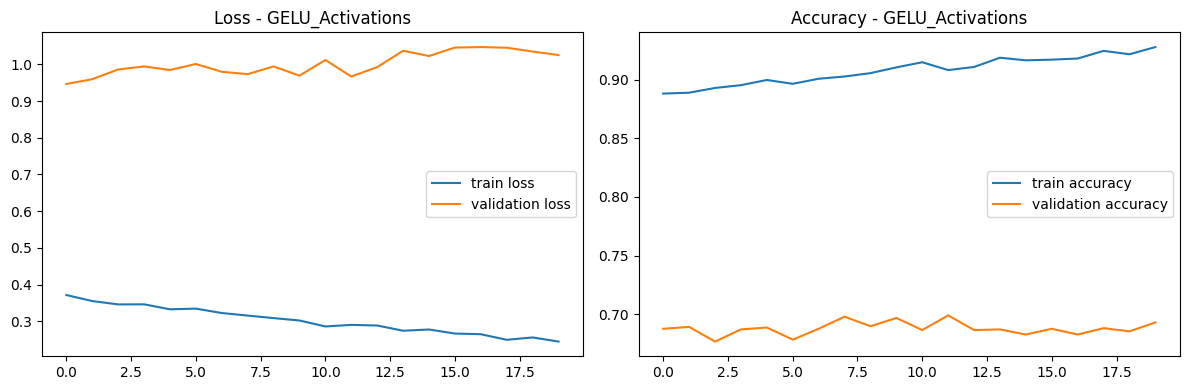

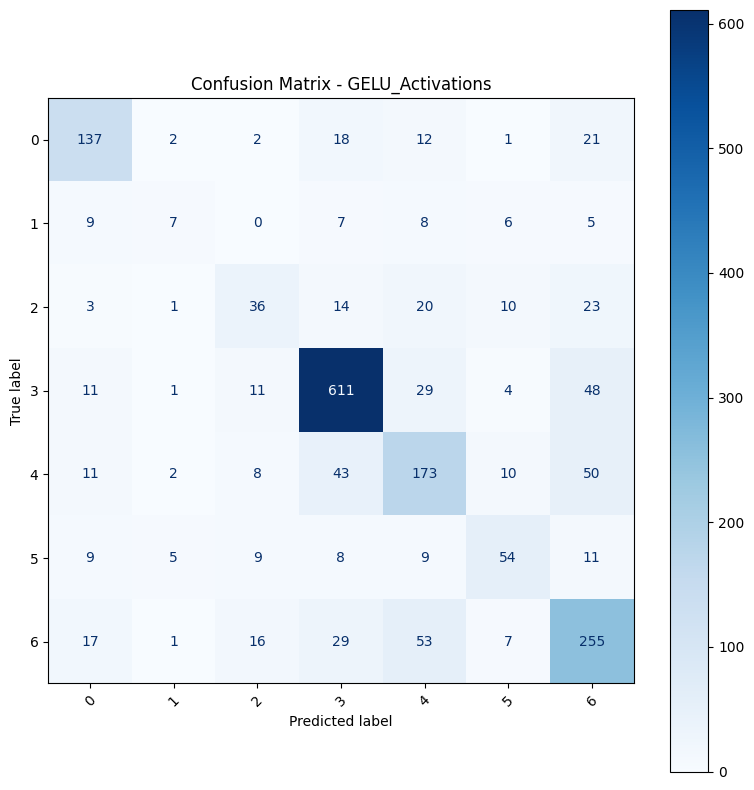

Best validation f1_macro: 0.5761


In [40]:
find_best_model(
    lista_modele=lista_de_modele,
    nume_modele=nume_pentru_modele,
    train_loader=datasets["facial_no_aug"][0],
    val_loader=datasets["facial_no_aug"][1],
    lr=1e-5,
    weight_decay=1e-3,
    num_epochs=20
)

## CEL MAI BUN MODEL MLP ALUNITE

In [41]:
mlp1 = SimpleMLPWitHDropout(num_classes=7, img_size=IMG_SIZE)
mlp2 = TwoLayerMLP(num_classes=7, img_size=IMG_SIZE)
mlp3 = BatchNormMLP(num_classes=7, img_size=IMG_SIZE)
mlp4 = GELUMLP(num_classes=7, img_size=IMG_SIZE)
mlp5 = LeakyReLUMLP(num_classes=7, img_size=IMG_SIZE)

lista_de_modele = [mlp1, mlp2, mlp3, mlp4, mlp5]
nume_pentru_modele = ["Simple_Dropout", "TwoLayer", "BatchNorm", "GELU_Activations", "LeakyReLU MLP"]

In [42]:
find_best_model(
    lista_modele=lista_de_modele,
    nume_modele=nume_pentru_modele,
    train_loader=datasets["medical_no_aug"][0],
    val_loader=datasets["medical_no_aug"][1],
    lr=1e-3,
    weight_decay=1e-5,
    num_epochs=20
)

[Simple_Dropout] Epoca 01 | train loss=3.8434 acc=0.606 f1_macro=0.239 f1_micro=0.606 | val loss=1.7757 acc=0.672 f1_macro=0.175 f1_micro=0.672
[Simple_Dropout] Epoca 02 | train loss=1.5455 acc=0.659 f1_macro=0.280 f1_micro=0.659 | val loss=1.5678 acc=0.675 f1_macro=0.245 f1_micro=0.675
[Simple_Dropout] Epoca 03 | train loss=1.2865 acc=0.675 f1_macro=0.311 f1_micro=0.675 | val loss=1.4960 acc=0.679 f1_macro=0.193 f1_micro=0.679
[Simple_Dropout] Epoca 04 | train loss=1.1618 acc=0.685 f1_macro=0.338 f1_micro=0.685 | val loss=1.1353 acc=0.668 f1_macro=0.281 f1_micro=0.668
[Simple_Dropout] Epoca 05 | train loss=1.0942 acc=0.691 f1_macro=0.345 f1_micro=0.691 | val loss=1.2672 acc=0.669 f1_macro=0.269 f1_micro=0.669
[Simple_Dropout] Epoca 06 | train loss=1.0143 acc=0.691 f1_macro=0.366 f1_micro=0.691 | val loss=1.2375 acc=0.697 f1_macro=0.312 f1_micro=0.697
[Simple_Dropout] Epoca 07 | train loss=0.9550 acc=0.697 f1_macro=0.397 f1_micro=0.697 | val loss=1.1555 acc=0.685 f1_macro=0.282 f1_micr

KeyboardInterrupt: 

## EXPERIMENTE PE CEL MAI BUN MODEL MLP CU DEZECHILIBRU DE CLASE

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_dataset_facial = datasets["facial_no_aug"][0].dataset
toate_etichetele_fata = [int(train_dataset_facial.annotations.iloc[i, 1]) - 1 for i in range(len(train_dataset_facial))]

train_dataset_medical = datasets["medical_no_aug"][0].dataset
toate_etichetele = [train_dataset_medical.class_to_idx[train_dataset_medical.annotations.iloc[i, 1]] for i in range(len(train_dataset_medical))]

criteriu_focal_fata = get_focal_loss(toate_etichetele_fata, device, gamma=2.0)

### FETE

In [ ]:
model_focal = GELUMLP(
    num_classes=7,
    img_size=IMG_SIZE
)

model_name = "GELUMLP_Facial_FocalLoss"

mlp_focal_facial_history = ruleaza_pipeline_complet(
    model=model_focal,
    train_loader=datasets["facial_no_aug"][0],
    val_loader=datasets["facial_no_aug"][1],
    model_name=model_name,
    criterion=criteriu_focal_fata,
    lr=1e-4,
    weight_decay=1e-4,
    num_epochs=20
)

afiseaza_rezultate_finale(
    model=model_focal,
    history=mlp_focal_facial_history,
    val_loader=datasets["facial_no_aug"][1],
    model_name=model_name
)

In [ ]:
sampler_balansat_fata = get_weighted_sampler(toate_etichetele_fata)
loader_train_sampler_fata = DataLoader(
    train_dataset_facial,
    batch_size=64,
    sampler=sampler_balansat_fata,
    drop_last=True
)

model_focal = GELUMLP(
    num_classes=7,
    img_size=IMG_SIZE
)

model_name = "GELUMLP_Facial_Sampler"

mlp_sampler_facial_history = ruleaza_pipeline_complet(
    model=model_focal,
    train_loader=loader_train_sampler_fata,
    val_loader=datasets["facial_no_aug"][1],
    model_name=model_name,
    criterion=None,
    lr=1e-4,
    weight_decay=1e-4,
    num_epochs=20
)

afiseaza_rezultate_finale(
    model=model_focal,
    history=mlp_sampler_facial_history,
    val_loader=datasets["facial_no_aug"][1],
    model_name=model_name
)

### ALUNITE

In [ ]:
criteriu_focal = get_focal_loss(toate_etichetele, device, gamma=2.0)

model_medical = LeakyReLUMLP(
    num_classes=7,
    img_size=IMG_SIZE
)

model_name = "LeakyReLUMLP_Medical_FocalLoss"

mlp_focal_medical_history = ruleaza_pipeline_complet(
    model=model_medical,
    train_loader=datasets["medical_no_aug"][0],
    val_loader=datasets["medical_no_aug"][1],
    model_name=model_name,
    criterion=criteriu_focal,
    lr=1e-3,
    weight_decay=1e-5,
    num_epochs=20
)

afiseaza_rezultate_finale(
    model=model_medical,
    history=mlp_focal_medical_history,
    val_loader=datasets["facial_no_aug"][1],
    model_name=model_name
)

In [ ]:
sampler_balansat = get_weighted_sampler(toate_etichetele)

loader_train_sampler = DataLoader(
    train_dataset_medical,
    batch_size=64,
    sampler=sampler_balansat,
    drop_last=True
)

model_medical = LeakyReLUMLP(
    num_classes=7,
    img_size=IMG_SIZE
)

model_name = "LeakyReLUMLP_Medical_Sampler"

mlp_sampler_medical_history = ruleaza_pipeline_complet(
    model=model_medical,
    train_loader=loader_train_sampler,
    val_loader=datasets["medical_no_aug"][1],
    model_name=model_name,
    criterion=None,
    lr=1e-3,
    weight_decay=1e-5,
    num_epochs=20
)

afiseaza_rezultate_finale(
    model=model_medical,
    history=mlp_sampler_medical_history,
    val_loader=datasets["facial_no_aug"][1],
    model_name=model_name
)

## CNN

In [ ]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes, first_kernel_size=3):
        super().__init__()

        padding_1 = first_kernel_size // 2  # ca să menținem dimensiunea spațială, padding e 1 pt kernel 3, și 2 pt kernel 5
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=first_kernel_size, padding=padding_1, bias=False),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1)
        )

        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        return self.classifier(x)


In [ ]:
class CNNWithBatchNorm(nn.Module):
    def __init__(self, num_classes, first_kernel_size=3):
        super().__init__()

        padding_1 = first_kernel_size // 2
        self.features = nn.Sequential(
            # Primul bloc convoluțional
            nn.Conv2d(3, 32, kernel_size=first_kernel_size, padding=padding_1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Al doilea bloc convoluțional
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Al treilea bloc convoluțional
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d(1)
        )
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        return self.classifier(x)

In [ ]:
class VGGLiteCNN(nn.Module):
    def __init__(self, num_classes=7, first_kernel_size=3):
        super().__init__()

        pad1 = first_kernel_size // 2

        self.features = nn.Sequential(
            # Strat 1
            nn.Conv2d(3, 32, kernel_size=first_kernel_size, padding=pad1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Strat 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Strat 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Strat 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        x = self.classifier(x)
        return x

In [ ]:
class ReceptiveEnhancerCNN(nn.Module):
    def __init__(self, num_classes=7, first_kernel_size=3):
        super().__init__()

        pad1 = first_kernel_size // 2

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=first_kernel_size, padding=pad1, bias=False),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(negative_slope=0.1, inplace=True),

            nn.Conv2d(32, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.LeakyReLU(negative_slope=0.1, inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            # Bloc 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(negative_slope=0.1, inplace=True),

            nn.Conv2d(64, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(negative_slope=0.1, inplace=True),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(64, 32),
            nn.LeakyReLU(negative_slope=0.1, inplace=True),
            nn.Linear(32, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        x = self.classifier(x)
        return x

In [ ]:
class WideShallowCNN(nn.Module):
    def __init__(self, num_classes=7, first_kernel_size=3):
        super().__init__()

        pad1 = first_kernel_size // 2
        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=first_kernel_size, padding=pad1, bias=False),
            nn.BatchNorm2d(64),
            nn.GELU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.GELU(),
            nn.MaxPool2d(kernel_size=3, stride=2, padding=1),

            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.GELU(),

            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.classifier = nn.Sequential(
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        x = self.classifier(x)
        return x

In [ ]:
# 4 Convolutional Layers and 2 Linear Layers using LeakyReLU
class MaxCapacityCNN(nn.Module):
    def __init__(self, num_classes=7, first_kernel_size=3):
        super().__init__()

        pad1 = first_kernel_size // 2

        self.features = nn.Sequential(
            nn.Conv2d(3, 64, kernel_size=first_kernel_size, padding=pad1, bias=False),
            nn.BatchNorm2d(64),
            nn.LeakyReLU(negative_slope=0.1, inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(negative_slope=0.1, inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(negative_slope=0.1, inplace=True),
            nn.MaxPool2d(kernel_size=2, stride=2),

            nn.Conv2d(256, 512, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(negative_slope=0.1, inplace=True),

            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Dropout(0.5),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.LeakyReLU(negative_slope=0.1, inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = x.flatten(1)
        x = self.classifier(x)
        return x

## AFLAREA CELUI MAI BUN CNN PENTRU FIECARE SET DE DATE

In [ ]:
print("=== COMPARAȚIE ARHITECTURI CNN - FEȚE ===")

m1 = SimpleCNN(num_classes=7, first_kernel_size=3)
m2 = CNNWithBatchNorm(num_classes=7, first_kernel_size=3)
m3 = VGGLiteCNN(num_classes=7, first_kernel_size=3)
m4 = ReceptiveEnhancerCNN(num_classes=7, first_kernel_size=3)
m5 = WideShallowCNN(num_classes=7, first_kernel_size=3)
m6 = MaxCapacityCNN(num_classes=7, first_kernel_size=3)

modele_fete = [m1, m2, m3, m4, m5, m6]
nume_fete = [
    "SimpleCNN_Fete",
    "BatchNormCNN_Fete",
    "VGGLite_Fete",
    "Enhancer_Fete",
    "WideShallow_Fete",
    "MaxCapacitye_Fete"
]

find_best_model(
    lista_modele=modele_fete,
    nume_modele=nume_fete,
    train_loader=datasets["facial_no_aug"][0],
    val_loader=datasets["facial_no_aug"][1],
    lr=1e-4,
    weight_decay=1e-4,
    num_epochs=20
)

In [ ]:
print("=== COMPARAȚIE ARHITECTURI CNN - ALUNIȚE ===")

# Instanțiem toate modelele cu kernel de 5
m1_med = SimpleCNN(num_classes=7, first_kernel_size=5)
m2_med = CNNWithBatchNorm(num_classes=7, first_kernel_size=5)
m3_med = VGGLiteCNN(num_classes=7, first_kernel_size=5)
m4_med = ReceptiveEnhancerCNN(num_classes=7, first_kernel_size=5)
m5_med = WideShallowCNN(num_classes=7, first_kernel_size=5)
m6_med = MaxCapacityCNN(num_classes=7, first_kernel_size=5)

modele_medical = [m1_med, m2_med, m3_med, m4_med, m5_med, m6_med]
nume_medical = [
    "SimpleCNN_Alunite",
    "BatchNormCNN_Alunite",
    "VGGLite_Alunite",
    "Enhancer_Alunite",
    "WideShallow_Alunite",
    "MaxCapacity_Alunite"
]

find_best_model(
    lista_modele=modele_medical,
    nume_modele=nume_medical,
    train_loader=datasets["medical_no_aug"][0],
    val_loader=datasets["medical_no_aug"][1],
    lr=1e-3,
    weight_decay=1e-5,
    num_epochs=20
)

## AUGMENTARI

In [ ]:
norm_fete = {
    "mean": [0.5752126091262171, 0.4497227663589234, 0.4012869135370431],
    "std": [0.26532880449272844, 0.24229550144470252, 0.24068486736909714]
}

norm_alunite = {
    "mean": [0.7646, 0.5464, 0.5712],
    "std": [0.1410, 0.1532, 0.1706]
}

def add_augmentations(datasets_dict):
    # Validation rămâne MEREU pe datele originale (fără augmentare)
    val_loader_fete = datasets_dict["facial_no_aug"][1]
    val_loader_alunite = datasets_dict["medical_no_aug"][1]

    # Dataseturile originale (fără augmentare) - le vom concatena cu cele augmentate
    ds_fete_original = datasets_dict["facial_no_aug"][0].dataset
    ds_alunite_original = datasets_dict["medical_no_aug"][0].dataset

    # === TRANSFORMS AUGMENTARE FETE ===
    trans_fete_geo = transforms.Compose([
        transforms.Resize((104, 104)),
        transforms.RandomCrop(IMG_SIZE),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=15),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_fete["mean"], std=norm_fete["std"])
    ])

    trans_fete_color = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.GaussianBlur(3, (0.1, 1.0)),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_fete["mean"], std=norm_fete["std"])
    ])

    trans_fete_all = transforms.Compose([
        transforms.Resize((104, 104)),
        transforms.RandomCrop(IMG_SIZE),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=15),
        transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
        transforms.GaussianBlur(3, (0.1, 1.0)),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_fete["mean"], std=norm_fete["std"])
    ])

    # === TRANSFORMS AUGMENTARE ALUNITE ===
    trans_alunite_geo = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomRotation(degrees=180),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_alunite["mean"], std=norm_alunite["std"])
    ])

    trans_alunite_color = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ColorJitter(brightness=0.1, contrast=0.1),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_alunite["mean"], std=norm_alunite["std"])
    ])

    trans_alunite_all = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomVerticalFlip(p=0.5),
        transforms.RandomRotation(degrees=180),
        transforms.ColorJitter(brightness=0.1, contrast=0.1),
        transforms.ToTensor(),
        transforms.Normalize(mean=norm_alunite["mean"], std=norm_alunite["std"])
    ])

    # === CREARE DATASETURI AUGMENTATE ===
    csv_fete = f"{datasets_dir}/you-re-on-candid-camera/splits/train.csv"
    dir_fete = f"{datasets_dir}/you-re-on-candid-camera"
    ds_fete_aug_geo = FacialExpressionDatasetBrut(csv_fete, dir_fete, trans_fete_geo)
    ds_fete_aug_color = FacialExpressionDatasetBrut(csv_fete, dir_fete, trans_fete_color)
    ds_fete_aug_all = FacialExpressionDatasetBrut(csv_fete, dir_fete, trans_fete_all)

    csv_alunite = f"{datasets_dir}/vai-de-pielea-mea/train.csv"
    dir_alunite = f"{datasets_dir}/vai-de-pielea-mea/train"
    ds_alunite_aug_geo = SkinLesionDatasetBrut(csv_alunite, dir_alunite, trans_alunite_geo)
    ds_alunite_aug_color = SkinLesionDatasetBrut(csv_alunite, dir_alunite, trans_alunite_color)
    ds_alunite_aug_all = SkinLesionDatasetBrut(csv_alunite, dir_alunite, trans_alunite_all)

    # === CONCATENARE: ORIGINAL + AUGMENTAT ===
    concat_fete_geo = ConcatDataset([ds_fete_original, ds_fete_aug_geo])
    concat_fete_color = ConcatDataset([ds_fete_original, ds_fete_aug_color])
    concat_fete_all = ConcatDataset([ds_fete_original, ds_fete_aug_all])

    concat_alunite_geo = ConcatDataset([ds_alunite_original, ds_alunite_aug_geo])
    concat_alunite_color = ConcatDataset([ds_alunite_original, ds_alunite_aug_color])
    concat_alunite_all = ConcatDataset([ds_alunite_original, ds_alunite_aug_all])

    # === LOADERE FINALE ===
    datasets_dict["facial_geo"]   = (make_dataloader(concat_fete_geo, batch_size=BATCH_SIZE, shuffle=True, drop_last=True), val_loader_fete)
    datasets_dict["facial_color"] = (make_dataloader(concat_fete_color, batch_size=BATCH_SIZE, shuffle=True, drop_last=True), val_loader_fete)
    datasets_dict["facial_all"]   = (make_dataloader(concat_fete_all, batch_size=BATCH_SIZE, shuffle=True, drop_last=True), val_loader_fete)

    datasets_dict["medical_geo"]   = (make_dataloader(concat_alunite_geo, batch_size=BATCH_SIZE, shuffle=True, drop_last=True), val_loader_alunite)
    datasets_dict["medical_color"] = (make_dataloader(concat_alunite_color, batch_size=BATCH_SIZE, shuffle=True, drop_last=True), val_loader_alunite)
    datasets_dict["medical_all"]   = (make_dataloader(concat_alunite_all, batch_size=BATCH_SIZE, shuffle=True, drop_last=True), val_loader_alunite)

## EXPERIMENTE AUGMENTARI

### ALUNITE

In [ ]:
print("=== RULARE - ALUNIȚE (AUGMENTARE GEO) ===")

vgg_cnn_medical = VGGLiteCNN(num_classes=7, first_kernel_size=5)

model_name = "VGG_CNN_GEO"

vgg_cnn_medical_history = ruleaza_pipeline_complet(
    model=vgg_cnn_medical,
    train_loader=datasets["medical_geo"][0],
    val_loader=datasets["medical_geo"][1],
    model_name=model_name,
    criterion=None,
    lr=1e-3,
    weight_decay=1e-5,
    num_epochs=20
)

afiseaza_rezultate_finale(
    model=vgg_cnn_medical,
    history=vgg_cnn_medical_history,
    val_loader=datasets["medical_geo"][1],
    model_name=model_name
)

In [ ]:
print("=== RULARE - ALUNIȚE (AUGMENTARE COLOR) ===")

vgg_cnn_medical = VGGLiteCNN(num_classes=7, first_kernel_size=5)

model_name = "VGG_CNN_COLOR"

vgg_cnn_medical_history= ruleaza_pipeline_complet(
    model=vgg_cnn_medical,
    train_loader=datasets["medical_color"][0],
    val_loader=datasets["medical_color"][1],
    model_name=model_name,
    criterion=None,
    lr=1e-3,
    weight_decay=1e-5,
    num_epochs=20
)

afiseaza_rezultate_finale(
    model=vgg_cnn_medical,
    history=vgg_cnn_medical_history,
    val_loader=datasets["medical_color"][1],
    model_name=model_name
)

In [ ]:
print("=== RULARE - ALUNIȚE (AUGMENTARE ALL) ===")

vgg_cnn_medical = VGGLiteCNN(num_classes=7, first_kernel_size=5)

model_name = "VGG_CNN_ALL"

vgg_cnn_medical_history= ruleaza_pipeline_complet(
    model=vgg_cnn_medical,
    train_loader=datasets["medical_color"][0],
    val_loader=datasets["medical_color"][1],
    model_name=model_name,
    criterion=None,
    lr=1e-3,
    weight_decay=1e-5,
    num_epochs=20
)

afiseaza_rezultate_finale(
    model=vgg_cnn_medical,
    history=vgg_cnn_medical_history,
    val_loader=datasets["medical_color"][1],
    model_name=model_name
)

### FETE

In [ ]:
print("=== RULARE - FETE (AUGMENTARE GEO) ===")

max_cnn_facial = MaxCapacityCNN(num_classes=7, first_kernel_size=3)

model_name = "MAX_CAPACITY_GEO"

max_cnn_facial_history= ruleaza_pipeline_complet(
    model=max_cnn_facial,
    train_loader=datasets["facial_geo"][0],
    val_loader=datasets["facial_geo"][1],
    model_name=model_name,
    criterion=None,
    lr=1e-3,
    weight_decay=1e-5,
    num_epochs=20
)

afiseaza_rezultate_finale(
    model=max_cnn_facial,
    history=max_cnn_facial_history,
    val_loader=datasets["facial_geo"][1],
    model_name=model_name
)

In [ ]:
print("=== RULARE - FETE (AUGMENTARE COLOR) ===")

max_cnn_facial = MaxCapacityCNN(num_classes=7, first_kernel_size=3)

model_name = "MAX_CAPACITY_COLOR"

max_cnn_facial_history= ruleaza_pipeline_complet(
    model=max_cnn_facial,
    train_loader=datasets["medical_color"][0],
    val_loader=datasets["medical_color"][1],
    model_name=model_name,
    criterion=None,
    lr=1e-4,
    weight_decay=1e-4,
    num_epochs=20
)

afiseaza_rezultate_finale(
    model=max_cnn_facial,
    history=max_cnn_facial_history,
    val_loader=datasets["medical_color"][1],
    model_name=model_name
)

In [ ]:
print("=== RULARE - FETE (AUGMENTARE ALL) ===")

max_cnn_medical = MaxCapacityCNN(num_classes=7, first_kernel_size=3)

model_name = "MAX_CAPACITY_ALL"

max_cnn_facial_history= ruleaza_pipeline_complet(
    model=max_cnn_medical,
    train_loader=datasets["medical_all"][0],
    val_loader=datasets["medical_all"][1],
    model_name=model_name,
    criterion=None,
    lr=1e-4,
    weight_decay=1e-4,
    num_epochs=20
)

afiseaza_rezultate_finale(
    model=max_cnn_medical,
    history=max_cnn_facial_history,
    val_loader=datasets["medical_all"][1],
    model_name=model_name
)

In [ ]:
print("=== FETE (GEO) + FOCAL LOSS pe MaxCapacityCNN ===")

model_focal_fete = MaxCapacityCNN(num_classes=7, first_kernel_size=3)
model_name = "MaxCapacityCNN_GEO_FocalLoss"

focal_fete_history = ruleaza_pipeline_complet(
    model=model_focal_fete,
    train_loader=datasets["facial_geo"][0],
    val_loader=datasets["facial_geo"][1],
    model_name=model_name,
    criterion=criteriu_focal_fata,
    lr=1e-4,
    weight_decay=1e-4,
    num_epochs=20
)

afiseaza_rezultate_finale(
    model=model_focal_fete,
    history=focal_fete_history,
    val_loader=datasets["facial_geo"][1],
    model_name=model_name,
    class_names=[f"Clasa {i}" for i in range(7)]
)

In [ ]:
print("=== FETE (GEO) + WEIGHTED SAMPLER pe MaxCapacityCNN ===")

toate_etichetele_fete_geo = toate_etichetele_fata * 2
sampler_balansat_fete_geo = get_weighted_sampler(toate_etichetele_fete_geo)

loader_sampler_fete_geo = DataLoader(
    datasets["facial_geo"][0].dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler_balansat_fete_geo,
    drop_last=True
)

model_sampler_fete = MaxCapacityCNN(num_classes=7, first_kernel_size=3)
model_name = "MaxCapacityCNN_GEO_Sampler"

sampler_fete_history = ruleaza_pipeline_complet(
    model=model_sampler_fete,
    train_loader=loader_sampler_fete_geo,
    val_loader=datasets["facial_geo"][1],
    model_name=model_name,
    criterion=None,
    lr=1e-4,
    weight_decay=1e-4,
    num_epochs=20
)

afiseaza_rezultate_finale(
    model=model_sampler_fete,
    history=sampler_fete_history,
    val_loader=datasets["facial_geo"][1],
    model_name=model_name,
    class_names=[f"Clasa {i}" for i in range(7)]
)

In [ ]:
print("=== ALUNITE (COLOR) + FOCAL LOSS pe VGGLiteCNN ===")

model_focal_medical = VGGLiteCNN(num_classes=7, first_kernel_size=5)
model_name = "VGGLiteCNN_COLOR_FocalLoss"

focal_medical_history = ruleaza_pipeline_complet(
    model=model_focal_medical,
    train_loader=datasets["medical_color"][0],
    val_loader=datasets["medical_color"][1],
    model_name=model_name,
    criterion=criteriu_focal,
    lr=1e-3,
    weight_decay=1e-5,
    num_epochs=20
)

afiseaza_rezultate_finale(
    model=model_focal_medical,
    history=focal_medical_history,
    val_loader=datasets["medical_color"][1],
    model_name=model_name,
    class_names=list(medical_train_no_aug_dataset.class_to_idx.keys())
)

In [ ]:
print("=== ALUNITE (COLOR) + WEIGHTED SAMPLER pe VGGLiteCNN ===")

toate_etichetele_medical_color = toate_etichetele * 2
sampler_balansat_medical_color = get_weighted_sampler(toate_etichetele_medical_color)

loader_sampler_medical_color = DataLoader(
    datasets["medical_color"][0].dataset,
    batch_size=BATCH_SIZE,
    sampler=sampler_balansat_medical_color,
    drop_last=True
)

model_sampler_medical = VGGLiteCNN(num_classes=7, first_kernel_size=5)
model_name = "VGGLiteCNN_COLOR_Sampler"

sampler_medical_history = ruleaza_pipeline_complet(
    model=model_sampler_medical,
    train_loader=loader_sampler_medical_color,
    val_loader=datasets["medical_color"][1],
    model_name=model_name,
    criterion=None,
    lr=1e-3,
    weight_decay=1e-5,
    num_epochs=20
)

afiseaza_rezultate_finale(
    model=model_sampler_medical,
    history=sampler_medical_history,
    val_loader=datasets["medical_color"][1],
    model_name=model_name,
    class_names=list(medical_train_no_aug_dataset.class_to_idx.keys())
)

## KAGGLE

In [ ]:
def train_model_blind(model, train_loader, num_epochs=20, lr=1e-3, weight_decay=1e-5, criterion=None):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    if criterion is None:
        criterion = nn.CrossEntropyLoss()

    print(f"Incepem antrenarea pentru {num_epochs} epoci (fara a calcula metrici, doar Loss)...")
    for epoch in range(num_epochs):
        model.train()
        running_loss = 0.0
        total = 0

        pbar = tqdm(train_loader, desc=f"Epoca {epoch+1}/{num_epochs}", leave=False)
        for images, labels in pbar:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()

            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)

            optimizer.step()

            running_loss += loss.item() * images.size(0)
            total += images.size(0)
            pbar.set_postfix({'loss': f"{loss.item():.4f}"})

        print(f"Epoca {epoch+1:02d}/{num_epochs} terminata. Train Loss mediu: {running_loss/total:.4f}")

    return model

In [50]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

def find_all_images(root_dir):
    img_dict = {}
    for dirpath, _, filenames in os.walk(root_dir):
        for f in filenames:
            if f.lower().endswith('.jpg'):
                img_dict[f] = os.path.join(dirpath, f)
    return img_dict

def build_submission_transform(mean=None, std=None, img_size=(224, 224)):
    mean = IMAGENET_MEAN if mean is None else mean
    std = IMAGENET_STD if std is None else std
    return transforms.Compose([
        transforms.Resize(img_size),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std)
    ])

In [49]:
# ResNet-18 final pipeline

def set_seed(seed=42):
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

set_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
if device.type == 'cuda':
    torch.backends.cudnn.benchmark = True


def make_fast_dataloader(dataset, batch_size, shuffle=False, sampler=None, drop_last=False, num_workers=2):
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle if sampler is None else False,
        sampler=sampler,
        num_workers=num_workers,
        pin_memory=(device.type == 'cuda'),
        persistent_workers=(num_workers > 0),
        drop_last=drop_last,
    )

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

FACE_IMAGE_SIZE = 128
SKIN_IMAGE_SIZE = 224

class PadToSquare:
    def __init__(self, fill=0):
        self.fill = fill

    def __call__(self, img):
        w, h = img.size
        if w == h:
            return img

        max_side = max(w, h)
        pad_left = (max_side - w) // 2
        pad_top = (max_side - h) // 2
        pad_right = max_side - w - pad_left
        pad_bottom = max_side - h - pad_top
        return transforms.functional.pad(img, (pad_left, pad_top, pad_right, pad_bottom), fill=self.fill)

def get_image_size(dataset_type):
    return FACE_IMAGE_SIZE if dataset_type == 'emotion' else SKIN_IMAGE_SIZE

def get_transforms(dataset_type='skin', image_size=None):
    mean = IMAGENET_MEAN
    std = IMAGENET_STD
    image_size = get_image_size(dataset_type) if image_size is None else image_size

    if dataset_type == 'skin':
        train_transform = transforms.Compose([
            PadToSquare(),
            transforms.Resize(int(image_size * 1.15)),
            transforms.RandomCrop(image_size),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomVerticalFlip(p=0.5),
            transforms.RandomRotation(degrees=180),
            transforms.ColorJitter(brightness=0.08, contrast=0.08, saturation=0.08),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std)
        ])
        val_transform = transforms.Compose([
            PadToSquare(),
            transforms.Resize(image_size),
            transforms.CenterCrop(image_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std)
        ])
    else:
        train_transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(degrees=10),
            transforms.RandomAffine(degrees=0, translate=(0.08, 0.08), scale=(0.95, 1.05)),
            transforms.ColorJitter(brightness=0.1, contrast=0.1, saturation=0.1),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std)
        ])
        val_transform = transforms.Compose([
            transforms.Resize((image_size, image_size)),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std)
        ])

    return train_transform, val_transform

def create_dataloaders(
    train_csv, val_csv, train_img_dir, val_img_dir,
    dataset_type='skin', batch_size=32, num_workers=2,
    use_weighted_sampler=False, image_size=None
):
    train_transform, val_transform = get_transforms(dataset_type, image_size=image_size)

    if dataset_type == 'emotion':
        train_dataset = FacialExpressionDatasetBrut(train_csv, train_img_dir, transform=train_transform)
        val_dataset = FacialExpressionDatasetBrut(val_csv, val_img_dir, transform=val_transform)
        class_names = [f'C{i}' for i in range(7)]
        labels = [int(train_dataset.annotations.iloc[i, 1]) - 1 for i in range(len(train_dataset))]
    else:
        train_dataset = SkinLesionDatasetBrut(train_csv, train_img_dir, transform=train_transform)
        val_dataset = SkinLesionDatasetBrut(val_csv, val_img_dir, transform=val_transform)
        class_names = list(train_dataset.class_to_idx.keys())
        labels = [train_dataset.class_to_idx[train_dataset.annotations.iloc[i, 1]] for i in range(len(train_dataset))]

    num_classes = len(class_names)
    class_counts = np.bincount(np.array(labels), minlength=num_classes).astype(np.float64)
    total = class_counts.sum()
    inv = total / (num_classes * np.maximum(class_counts, 1))
    weights_np = np.sqrt(inv)
    weights_np = weights_np / weights_np.mean()
    class_weights = torch.tensor(weights_np, dtype=torch.float32)

    print('Class distribution:')
    for i, count in enumerate(class_counts):
        print(f'  Class {i} ({class_names[i]}): {count} samples (weight: {class_weights[i]:.3f})')

    if use_weighted_sampler:
        sample_weights = class_weights[np.array(labels)].cpu().numpy()
        sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(train_dataset), replacement=True)
        train_loader = make_fast_dataloader(train_dataset, batch_size=batch_size, sampler=sampler, num_workers=num_workers)
    else:
        train_loader = make_fast_dataloader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers, drop_last=True)

    val_loader = make_fast_dataloader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=num_workers)
    return train_loader, val_loader, class_weights, class_names

def load_pretrained_model(model_name, num_classes, device, freeze_backbone=False):
    print(f'Loading {model_name} pre-trained on ImageNet...')
    if model_name != 'resnet18':
        raise ValueError('Model not supported. Use resnet18.')

    model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
    in_features = model.fc.in_features
    model.fc = nn.Sequential(nn.Dropout(0.35), nn.Linear(in_features, num_classes))
    print(f'  ResNet-18 loaded. Replaced FC: 512 -> Dropout(0.35) -> {num_classes}')

    if freeze_backbone:
        for name, param in model.named_parameters():
            if not name.startswith('fc.'):
                param.requires_grad = False
        print('  Backbone FROZEN (only head trainable)')
    else:
        print('  Backbone UNFROZEN (all params trainable)')

    return model.to(device)

def create_optimizer_with_differential_lr(model, model_name, backbone_lr=8e-6, head_lr=8e-5, weight_decay=1e-4):
    head_params = [p for name, p in model.named_parameters() if name.startswith('fc.') and p.requires_grad]
    backbone_params = [p for name, p in model.named_parameters() if not name.startswith('fc.') and p.requires_grad]
    groups = [{'params': head_params, 'lr': head_lr}]
    if backbone_params:
        groups.append({'params': backbone_params, 'lr': backbone_lr})
    return optim.AdamW(groups, weight_decay=weight_decay)

def build_criterion(criterion_name, class_weights, device):
    weights = class_weights.to(device)
    if criterion_name == 'focal':
        return FocalLoss(alpha=weights, gamma=1.5)
    if criterion_name == 'weighted_ce':
        return nn.CrossEntropyLoss(weight=weights)
    if criterion_name == 'ce':
        return nn.CrossEntropyLoss()
    raise ValueError(f'Unsupported criterion: {criterion_name}')

def train_one_epoch(model, train_loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    pbar = tqdm(train_loader, desc='Training', leave=False)
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        correct += predicted.eq(labels).sum().item()
        total += labels.size(0)
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})

    return running_loss / total, correct / total

@torch.no_grad()
def evaluate(model, val_loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []

    pbar = tqdm(val_loader, desc='Evaluating', leave=False)
    for images, labels in pbar:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            outputs = model(images)
            loss = criterion(outputs, labels)

        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        correct += predicted.eq(labels).sum().item()
        total += labels.size(0)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

    return running_loss / total, correct / total, np.array(all_preds), np.array(all_labels)

def finetune_pretrained_model(
    model_name, train_loader, val_loader, num_classes, class_weights, class_names,
    num_epochs=40, head_epochs=5, use_warmup=True, device='cuda',
    save_dir='/kaggle/working/checkpoints', criterion_name='focal'
):
    os.makedirs(save_dir, exist_ok=True)
    criterion = build_criterion(criterion_name, class_weights, device)

    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': [],
        'val_f1_macro': [], 'val_f1_weighted': [],
        'lr': []
    }
    best_f1, best_model_state, best_epoch = 0, None, 0

    if use_warmup:
        print(f'[STAGE 1] Training HEAD only ({head_epochs} epochs, backbone FROZEN)')
        model = load_pretrained_model(model_name, num_classes, device, freeze_backbone=True)
        optimizer = create_optimizer_with_differential_lr(model, model_name, backbone_lr=0, head_lr=5e-4, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(head_epochs, 1), eta_min=1e-7)

        for epoch in range(head_epochs):
            train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
            val_loss, val_acc, val_preds, val_labels = evaluate(model, val_loader, criterion, device)
            f1_m = f1_score(val_labels, val_preds, average='macro', zero_division=0)
            f1_w = f1_score(val_labels, val_preds, average='weighted', zero_division=0)

            history['train_loss'].append(train_loss); history['train_acc'].append(train_acc)
            history['val_loss'].append(val_loss); history['val_acc'].append(val_acc)
            history['val_f1_macro'].append(f1_m); history['val_f1_weighted'].append(f1_w)
            history['lr'].append(optimizer.param_groups[0]['lr'])

            if f1_m > best_f1:
                best_f1 = f1_m
                best_model_state = copy.deepcopy(model.state_dict())
                best_epoch = epoch + 1

            scheduler.step()
            print(f"Head {epoch+1:02d}/{head_epochs} | TrL:{train_loss:.4f} TrA:{train_acc:.3f} | Vl:{val_loss:.4f} Va:{val_acc:.3f} | F1:{f1_m:.3f} | LR:{optimizer.param_groups[0]['lr']:.1e}")

        for param in model.parameters():
            param.requires_grad = True
        print(f'[STAGE 2] Fine-tuning ALL layers ({num_epochs} epochs, backbone UNFROZEN)')
    else:
        print(f'[NO WARMUP] Fine-tuning ALL layers ({num_epochs} epochs)')
        model = load_pretrained_model(model_name, num_classes, device, freeze_backbone=False)

    optimizer = create_optimizer_with_differential_lr(model, model_name, backbone_lr=1e-5, head_lr=1e-4, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(num_epochs, 1), eta_min=1e-7)
    patience_counter = 0
    early_stop_patience = 10

    for epoch in range(num_epochs):
        train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
        val_loss, val_acc, val_preds, val_labels = evaluate(model, val_loader, criterion, device)
        f1_m = f1_score(val_labels, val_preds, average='macro', zero_division=0)
        f1_w = f1_score(val_labels, val_preds, average='weighted', zero_division=0)

        history['train_loss'].append(train_loss); history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss); history['val_acc'].append(val_acc)
        history['val_f1_macro'].append(f1_m); history['val_f1_weighted'].append(f1_w)
        history['lr'].append(optimizer.param_groups[0]['lr'])

        ep_label = (head_epochs + epoch + 1) if use_warmup else (epoch + 1)
        if f1_m > best_f1:
            best_f1 = f1_m
            best_model_state = copy.deepcopy(model.state_dict())
            best_epoch = ep_label
            patience_counter = 0
        else:
            patience_counter += 1

        scheduler.step()
        print(f"FT {epoch+1:02d}/{num_epochs} | TrL:{train_loss:.4f} TrA:{train_acc:.3f} | Vl:{val_loss:.4f} Va:{val_acc:.3f} | F1:{f1_m:.3f} | LR:{optimizer.param_groups[0]['lr']:.1e}")

        if patience_counter >= early_stop_patience:
            print(f'Early stop after {epoch+1} epochs without improvement.')
            break

    if best_model_state is not None:
        model.load_state_dict(best_model_state)
    torch.save(model.state_dict(), os.path.join(save_dir, f'{model_name}_best.pt'))
    print(f'Best F1-macro: {best_f1:.4f} at epoch {best_epoch}')
    return model, history

def find_all_images(root_dir):
    img_dict = {}
    for dirpath, _, filenames in os.walk(root_dir):
        for f in filenames:
            if f.lower().endswith('.jpg'):
                img_dict[f] = os.path.join(dirpath, f)
    return img_dict

def build_submission_transform(mean=None, std=None, img_size=(224, 224), dataset_type='skin'):
    mean = IMAGENET_MEAN if mean is None else mean
    std = IMAGENET_STD if std is None else std
    if dataset_type == 'skin':
        return transforms.Compose([
            PadToSquare(),
            transforms.Resize(img_size),
            transforms.CenterCrop(img_size),
            transforms.ToTensor(),
            transforms.Normalize(mean=mean, std=std)
        ])
    return transforms.Compose([
        transforms.Resize((img_size, img_size)),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std)
    ])

def get_resnet_tta_transforms(img_size=224, dataset_type='skin'):
    if dataset_type == 'skin':
        return [
            build_submission_transform(mean=IMAGENET_MEAN, std=IMAGENET_STD, img_size=img_size, dataset_type='skin'),
            transforms.Compose([
                PadToSquare(),
                transforms.Resize(int(img_size * 1.1)),
                transforms.CenterCrop(img_size),
                transforms.RandomHorizontalFlip(p=1.0),
                transforms.ToTensor(),
                transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
            ]),
            transforms.Compose([
                PadToSquare(),
                transforms.Resize(int(img_size * 1.15)),
                transforms.FiveCrop(img_size)
            ])
        ]
    return [
        build_submission_transform(mean=IMAGENET_MEAN, std=IMAGENET_STD, img_size=img_size, dataset_type='emotion'),
        transforms.Compose([
            transforms.Resize((img_size, img_size)),
            transforms.RandomHorizontalFlip(p=1.0),
            transforms.ToTensor(),
            transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
        ])
    ]

@torch.no_grad()
def collect_predictions(model, loader, device='cuda'):
    model.eval()
    preds, labels = [], []
    for images, target in tqdm(loader, leave=False):
        logits = model(images.to(device))
        predicted = logits.argmax(dim=1).cpu().numpy()
        preds.extend(predicted)
        labels.extend(target.numpy())
    return np.array(preds), np.array(labels)

@torch.no_grad()
def predict_batch_with_transform(model, images, transform_spec, device='cuda'):
    if isinstance(transform_spec, transforms.Compose) and any(type(t).__name__ == 'FiveCrop' for t in transform_spec.transforms):
        prefix = []
        for t in transform_spec.transforms:
            if type(t).__name__ == 'FiveCrop':
                break
            prefix.append(t)
        suffix = []
        seen_crop = False
        for t in transform_spec.transforms:
            if seen_crop:
                suffix.append(t)
            elif type(t).__name__ == 'FiveCrop':
                seen_crop = True

        probs_all = []
        for image in images:
            image = image.cpu()
            pil = transforms.ToPILImage()(image)
            for t in prefix:
                pil = t(pil)
            crops = transforms.FiveCrop(get_image_size('skin'))(pil)
            crop_tensors = torch.stack([transforms.Compose(suffix)(crop) for crop in crops]).to(device)
            probs = torch.softmax(model(crop_tensors), dim=1).mean(dim=0)
            probs_all.append(probs.cpu())
        return torch.stack(probs_all)

    raise RuntimeError('Batch TTA helper should not be called directly for this transform')

@torch.no_grad()
def collect_tta_predictions(model, dataset, device='cuda', batch_size=32, dataset_type='skin'):
    model.eval()
    img_size = get_image_size(dataset_type)
    tta_transforms = get_resnet_tta_transforms(img_size=img_size, dataset_type=dataset_type)
    original_transform = dataset.transform
    probs_sum = None
    labels = None

    try:
        for tta_transform in tta_transforms:
            dataset.transform = tta_transform
            loader = make_fast_dataloader(dataset, batch_size=batch_size, shuffle=False, num_workers=0)
            probs_list, labels_list = [], []

            for images, target in tqdm(loader, leave=False):
                if isinstance(tta_transform, transforms.Compose) and any(type(t).__name__ == 'FiveCrop' for t in tta_transform.transforms):
                    batch_probs = predict_batch_with_transform(model, images, tta_transform, device=device)
                else:
                    batch_probs = torch.softmax(model(images.to(device)), dim=1).cpu()
                probs_list.append(batch_probs)
                labels_list.extend(target.numpy())

            probs = torch.cat(probs_list, dim=0)
            probs_sum = probs if probs_sum is None else (probs_sum + probs)
            if labels is None:
                labels = np.array(labels_list)
    finally:
        dataset.transform = original_transform

    avg_probs = probs_sum / len(tta_transforms)
    preds = avg_probs.argmax(dim=1).numpy()
    return preds, labels

def summarize_resnet_variants(dataset_name, val_loader, class_names, variants, device='cuda', dataset_type='skin'):
    rows = []
    for variant_name, variant_data in variants.items():
        model = variant_data['model']
        history = variant_data['history']
        use_warmup = variant_data['use_warmup']

        plain_preds, plain_labels = collect_predictions(model, val_loader, device=device)
        plain_f1 = f1_score(plain_labels, plain_preds, average='macro', zero_division=0)
        plain_acc = accuracy_score(plain_labels, plain_preds)
        best_epoch = int(np.argmax(history['val_f1_macro']) + 1)
        rows.append({'dataset': dataset_name, 'variant': variant_name, 'strategy': 'plain', 'use_warmup': use_warmup, 'best_epoch': best_epoch, 'f1_macro': plain_f1, 'accuracy': plain_acc})

        tta_preds, tta_labels = collect_tta_predictions(model, val_loader.dataset, device=device, batch_size=val_loader.batch_size, dataset_type=dataset_type)
        tta_f1 = f1_score(tta_labels, tta_preds, average='macro', zero_division=0)
        tta_acc = accuracy_score(tta_labels, tta_preds)
        rows.append({'dataset': dataset_name, 'variant': variant_name, 'strategy': 'tta', 'use_warmup': use_warmup, 'best_epoch': best_epoch, 'f1_macro': tta_f1, 'accuracy': tta_acc})

    results = pd.DataFrame(rows).sort_values(by=['f1_macro', 'accuracy'], ascending=False).reset_index(drop=True)
    best_row = results.iloc[0].to_dict()
    print(f'\n=== ResNet selection for {dataset_name} ===')
    display(results)
    print(f"Selected variant: {best_row['variant']} | strategy: {best_row['strategy']} | F1-macro: {best_row['f1_macro']:.4f} | accuracy: {best_row['accuracy']:.4f}")
    return results, best_row

def create_full_training_loader(
    train_csv, val_csv, train_img_dir, val_img_dir,
    dataset_type='skin', batch_size=32, num_workers=2,
    use_weighted_sampler=True, image_size=None
):
    train_transform, _ = get_transforms(dataset_type=dataset_type, image_size=image_size)
    if dataset_type == 'emotion':
        train_dataset = FacialExpressionDatasetBrut(train_csv, train_img_dir, transform=train_transform)
        val_dataset = FacialExpressionDatasetBrut(val_csv, val_img_dir, transform=train_transform)
        class_names = [f'C{i}' for i in range(7)]
        labels = [int(train_dataset.annotations.iloc[i, 1]) - 1 for i in range(len(train_dataset))]
        labels.extend(int(val_dataset.annotations.iloc[i, 1]) - 1 for i in range(len(val_dataset)))
    else:
        train_dataset = SkinLesionDatasetBrut(train_csv, train_img_dir, transform=train_transform)
        val_dataset = SkinLesionDatasetBrut(val_csv, val_img_dir, transform=train_transform)
        class_names = list(train_dataset.class_to_idx.keys())
        labels = [train_dataset.class_to_idx[train_dataset.annotations.iloc[i, 1]] for i in range(len(train_dataset))]
        labels.extend(val_dataset.class_to_idx[val_dataset.annotations.iloc[i, 1]] for i in range(len(val_dataset)))

    full_dataset = ConcatDataset([train_dataset, val_dataset])
    num_classes = len(class_names)
    class_counts = np.bincount(np.array(labels), minlength=num_classes).astype(np.float64)
    total = class_counts.sum()
    inv = total / (num_classes * np.maximum(class_counts, 1))
    weights_np = np.sqrt(inv)
    weights_np = weights_np / weights_np.mean()
    class_weights = torch.tensor(weights_np, dtype=torch.float32)

    if use_weighted_sampler:
        sample_weights = class_weights[np.array(labels)].cpu().numpy()
        sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(full_dataset), replacement=True)
        loader = make_fast_dataloader(full_dataset, batch_size=batch_size, sampler=sampler, num_workers=num_workers)
    else:
        loader = make_fast_dataloader(full_dataset, batch_size=batch_size, shuffle=True, num_workers=num_workers, drop_last=True)

    return loader, class_weights, class_names

def finetune_pretrained_model_full_data(
    model_name, train_loader, num_classes, class_weights,
    full_finetune_epochs, head_epochs=0, use_warmup=False,
    device='cuda', criterion_name='focal'
):
    criterion = build_criterion(criterion_name, class_weights, device)
    if use_warmup and head_epochs > 0:
        print(f'\n[FINAL TRAIN] Stage 1 warmup for {head_epochs} epochs')
        model = load_pretrained_model(model_name, num_classes, device, freeze_backbone=True)
        optimizer = create_optimizer_with_differential_lr(model, model_name, backbone_lr=0, head_lr=5e-4, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(head_epochs, 1), eta_min=1e-7)
        for epoch in range(head_epochs):
            train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
            scheduler.step()
            print(f'Warmup {epoch+1:02d}/{head_epochs} | TrL:{train_loss:.4f} | TrA:{train_acc:.3f}')
        for param in model.parameters():
            param.requires_grad = True
    else:
        model = load_pretrained_model(model_name, num_classes, device, freeze_backbone=False)

    if full_finetune_epochs > 0:
        print(f'\n[FINAL TRAIN] Stage 2 fine-tune for {full_finetune_epochs} epochs')
        optimizer = create_optimizer_with_differential_lr(model, model_name, backbone_lr=1e-5, head_lr=1e-4, weight_decay=1e-4)
        scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(full_finetune_epochs, 1), eta_min=1e-7)
        for epoch in range(full_finetune_epochs):
            train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
            scheduler.step()
            print(f'Full {epoch+1:02d}/{full_finetune_epochs} | TrL:{train_loss:.4f} | TrA:{train_acc:.3f}')
    return model

def retrain_best_resnet_on_full_data(
    selection, train_csv, val_csv, train_img_dir, val_img_dir,
    dataset_type, batch_size=32, num_workers=2,
    use_weighted_sampler=True, device='cuda', criterion_name='focal'
):
    total_epochs = int(selection['best_epoch'])
    use_warmup = bool(selection['use_warmup'])
    if use_warmup:
        selected_head_epochs = min(5, total_epochs)
        selected_full_epochs = max(total_epochs - selected_head_epochs, 0)
    else:
        selected_head_epochs = 0
        selected_full_epochs = total_epochs

    full_loader, class_weights, class_names = create_full_training_loader(
        train_csv=train_csv, val_csv=val_csv, train_img_dir=train_img_dir, val_img_dir=val_img_dir,
        dataset_type=dataset_type, batch_size=batch_size, num_workers=num_workers,
        use_weighted_sampler=use_weighted_sampler, image_size=get_image_size(dataset_type)
    )
    model = finetune_pretrained_model_full_data(
        model_name='resnet18', train_loader=full_loader, num_classes=len(class_names),
        class_weights=class_weights, full_finetune_epochs=selected_full_epochs,
        head_epochs=selected_head_epochs, use_warmup=use_warmup, device=device,
        criterion_name=criterion_name
    )
    metadata = {
        'strategy': selection['strategy'], 'use_warmup': use_warmup, 'best_epoch': total_epochs,
        'head_epochs': selected_head_epochs, 'full_finetune_epochs': selected_full_epochs,
        'class_names': class_names
    }
    return model, metadata

@torch.no_grad()
def predict_image_with_transforms(model, image, transforms_list, device='cuda'):
    probs_sum = None
    for transform in transforms_list:
        if isinstance(transform, transforms.Compose) and any(type(t).__name__ == 'FiveCrop' for t in transform.transforms):
            prefix = []
            suffix = []
            seen_crop = False
            crop_size = None
            for t in transform.transforms:
                if type(t).__name__ == 'FiveCrop':
                    seen_crop = True
                    crop_size = t.size if isinstance(t.size, int) else t.size[0]
                    continue
                if seen_crop:
                    suffix.append(t)
                else:
                    prefix.append(t)
            for t in prefix:
                image = t(image)
            crops = transforms.FiveCrop(crop_size)(image)
            crop_tensors = torch.stack([transforms.Compose(suffix)(crop) for crop in crops]).to(device)
            probs = torch.softmax(model(crop_tensors), dim=1).mean(dim=0, keepdim=True)
        else:
            img_tensor = transform(image).unsqueeze(0).to(device)
            probs = torch.softmax(model(img_tensor), dim=1)
        probs_sum = probs if probs_sum is None else (probs_sum + probs)
    avg_probs = probs_sum / len(transforms_list)
    return avg_probs.squeeze(0).cpu().numpy()

In [51]:
def generate_kaggle_submission_emotion_resnet(model, model_name, device='cuda', img_size=None, use_tta=False):
    model.eval()
    model = model.to(device)
    img_size = FACE_IMAGE_SIZE if img_size is None else img_size
    remote_csv = f'{datasets_dir}/you-re-on-candid-camera/splits/remote_test.csv'
    img_root = f'{datasets_dir}/you-re-on-candid-camera'
    df = pd.read_csv(remote_csv)
    ids = df['id'].tolist()
    transforms_list = get_resnet_tta_transforms(img_size=img_size, dataset_type='emotion') if use_tta else [build_submission_transform(mean=IMAGENET_MEAN, std=IMAGENET_STD, img_size=img_size, dataset_type='emotion')]
    print('Cautam pozele de test prin foldere (Candid Camera)...')
    img_paths_dict = find_all_images(img_root)
    preds = []
    with torch.no_grad():
        for img_name in tqdm(ids, desc='Predicting remote test'):
            img_path = img_paths_dict.get(img_name, os.path.join(img_root, 'DATASET', 'test', img_name))
            image = Image.open(img_path).convert('RGB')
            probs = predict_image_with_transforms(model, image, transforms_list, device=device)
            preds.append(int(np.argmax(probs)) + 1)
    suffix = 'tta' if use_tta else 'plain'
    submission = pd.DataFrame({'id': ids, 'label': preds})
    out_path = f'submission_{model_name}_emotion_{suffix}.csv'
    submission.to_csv(out_path, index=False)
    print(f'Submisie salvata: {out_path}')
    return submission

def generate_kaggle_submission_skin_resnet(model, model_name, device='cuda', img_size=None, use_tta=False):
    model.eval()
    model = model.to(device)
    img_size = SKIN_IMAGE_SIZE if img_size is None else img_size
    kaggle_csv = f'{datasets_dir}/vai-de-pielea-mea/kaggle_test.csv'
    img_root = f'{datasets_dir}/vai-de-pielea-mea'
    df = pd.read_csv(kaggle_csv)
    col_name = 'Imagine' if 'Imagine' in df.columns else 'imagine'
    img_names = df[col_name].tolist()
    transforms_list = get_resnet_tta_transforms(img_size=img_size, dataset_type='skin') if use_tta else [build_submission_transform(mean=IMAGENET_MEAN, std=IMAGENET_STD, img_size=img_size, dataset_type='skin')]
    print('Cautam pozele de test prin foldere (Vai de pielea mea)...')
    img_paths_dict = find_all_images(img_root)
    preds = []
    with torch.no_grad():
        for img_name in tqdm(img_names, desc='Predicting kaggle test'):
            img_path = img_paths_dict.get(img_name, os.path.join(img_root, 'kaggle_test', img_name))
            image = Image.open(img_path).convert('RGB')
            probs = predict_image_with_transforms(model, image, transforms_list, device=device)
            preds.append(int(np.argmax(probs)))
    suffix = 'tta' if use_tta else 'plain'
    submission = pd.DataFrame({'Id': img_names, 'Prediction': preds})
    out_path = f'submission_{model_name}_skin_{suffix}.csv'
    submission.to_csv(out_path, index=False)
    print(f'Submisie salvata: {out_path}')
    return submission

In [ ]:
print(">>> ANTRENARE RESNET-18 - FETE <<<")

emotion_train_loader, emotion_val_loader, emotion_class_weights, emotion_class_names = create_dataloaders(
    train_csv=f"{datasets_dir}/you-re-on-candid-camera/splits/train.csv",
    val_csv=f"{datasets_dir}/you-re-on-candid-camera/splits/local_test.csv",
    train_img_dir=f"{datasets_dir}/you-re-on-candid-camera",
    val_img_dir=f"{datasets_dir}/you-re-on-candid-camera",
    dataset_type='emotion',
    batch_size=64,
    use_weighted_sampler=False,
    image_size=FACE_IMAGE_SIZE
)

print("--- Antrenare FARA Warmup (Direct Fine-Tune) ---")
resnet18_emotion_no_warmup, history_resnet18_emotion_no_warmup = finetune_pretrained_model(
    model_name='resnet18',
    train_loader=emotion_train_loader,
    val_loader=emotion_val_loader,
    num_classes=len(emotion_class_names),
    class_weights=emotion_class_weights,
    class_names=emotion_class_names,
    num_epochs=45,
    head_epochs=5,
    use_warmup=False,
    device=device,
    criterion_name='ce'
)

print("--- Antrenare CU Warmup (Two-Stage) ---")
resnet18_emotion_warmup, history_resnet18_emotion_warmup = finetune_pretrained_model(
    model_name='resnet18',
    train_loader=emotion_train_loader,
    val_loader=emotion_val_loader,
    num_classes=len(emotion_class_names),
    class_weights=emotion_class_weights,
    class_names=emotion_class_names,
    num_epochs=45,
    head_epochs=5,
    use_warmup=True,
    device=device,
    criterion_name='ce'
)

>>> ANTRENARE RESNET-18 - FETE <<<
Class distribution:
  Class 0 (C0): 1097.0 samples (weight: 0.889)
  Class 1 (C1): 239.0 samples (weight: 1.904)
  Class 2 (C2): 610.0 samples (weight: 1.192)
  Class 3 (C3): 4057.0 samples (weight: 0.462)
  Class 4 (C4): 1685.0 samples (weight: 0.717)
  Class 5 (C5): 600.0 samples (weight: 1.202)
  Class 6 (C6): 2146.0 samples (weight: 0.635)
--- Antrenare FARA Warmup (Direct Fine-Tune) ---
[NO WARMUP] Fine-tuning ALL layers (45 epochs)
Loading resnet18 pre-trained on ImageNet...
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 192MB/s]


  ResNet-18 loaded. Replaced FC: 512 -> Dropout(0.35) -> 7
  Backbone UNFROZEN (all params trainable)


Training:   0%|          | 0/163 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/29 [00:00<?, ?it/s]

FT 01/45 | TrL:1.6476 TrA:0.401 | Vl:1.3887 Va:0.485 | F1:0.292 | LR:1.0e-04


... (252 outputs left out)

Training:   0%|          | 0/163 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/29 [00:00<?, ?it/s]

FT 36/45 | TrL:0.3845 TrA:0.861 | Vl:0.6764 Va:0.772 | F1:0.673 | LR:9.6e-06


Training:   0%|          | 0/163 [00:00<?, ?it/s]

In [ ]:
print(">>> ANTRENARE RESNET-18 - ALUNITE <<<")

skin_train_loader, skin_val_loader, skin_class_weights, skin_class_names = create_dataloaders(
    train_csv=f"{datasets_dir}/vai-de-pielea-mea/train.csv",
    val_csv=f"{datasets_dir}/vai-de-pielea-mea/test.csv",
    train_img_dir=f"{datasets_dir}/vai-de-pielea-mea/train",
    val_img_dir=f"{datasets_dir}/vai-de-pielea-mea/test",
    dataset_type='skin',
    batch_size=32,
    use_weighted_sampler=False,
    image_size=SKIN_IMAGE_SIZE
)

print("--- Antrenare FARA Warmup (Direct Fine-Tune) ---")
resnet18_skin_no_warmup, history_resnet18_skin_no_warmup = finetune_pretrained_model(
    model_name='resnet18',
    train_loader=skin_train_loader,
    val_loader=skin_val_loader,
    num_classes=len(skin_class_names),
    class_weights=skin_class_weights,
    class_names=skin_class_names,
    num_epochs=45,
    head_epochs=5,
    use_warmup=False,
    device=device,
    criterion_name='weighted_ce'
)

print("--- Antrenare CU Warmup (Two-Stage) ---")
resnet18_skin_warmup, history_resnet18_skin_warmup = finetune_pretrained_model(
    model_name='resnet18',
    train_loader=skin_train_loader,
    val_loader=skin_val_loader,
    num_classes=len(skin_class_names),
    class_weights=skin_class_weights,
    class_names=skin_class_names,
    num_epochs=45,
    head_epochs=5,
    use_warmup=True,
    device=device,
    criterion_name='weighted_ce'
)

In [ ]:
def plot_resnet_histories(histories, title):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    fig.suptitle(title, fontsize=16)

    # Loss Plot
    for name, hist in histories.items():
        axes[0].plot(hist['train_loss'], label=f'{name} (Train)')
        axes[0].plot(hist['val_loss'], '--', label=f'{name} (Val)')
    axes[0].set_title('Loss History')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].legend()
    axes[0].grid(True)

    # F1-Macro Plot
    for name, hist in histories.items():
        axes[1].plot(hist['val_f1_macro'], label=f'{name} (Val F1)')
    axes[1].set_title('Validation F1-Macro History')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('F1-Macro')
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

# Visualization for Emotion Dataset
if 'history_resnet18_emotion_no_warmup' in globals() and 'history_resnet18_emotion_warmup' in globals():
    plot_resnet_histories({
        'No Warmup': history_resnet18_emotion_no_warmup,
        'With Warmup': history_resnet18_emotion_warmup
    }, 'ResNet-18 Emotion Classification - Training Comparison')

# Visualization for Skin Lesion Dataset
if 'history_resnet18_skin_no_warmup' in globals() and 'history_resnet18_skin_warmup' in globals():
    plot_resnet_histories({
        'No Warmup': history_resnet18_skin_no_warmup,
        'With Warmup': history_resnet18_skin_warmup
    }, 'ResNet-18 Skin Lesion Classification - Training Comparison')

In [ ]:
print(">>> SELECTIE RESNET-18 - FETE <<<")

resnet_selection_emotion_df, best_resnet_emotion = summarize_resnet_variants(
    dataset_name='you-re-on-candid-camera',
    val_loader=emotion_val_loader,
    class_names=emotion_class_names,
    variants={
        'no_warmup': {
            'model': resnet18_emotion_no_warmup,
            'history': history_resnet18_emotion_no_warmup,
            'use_warmup': False
        },
        'warmup': {
            'model': resnet18_emotion_warmup,
            'history': history_resnet18_emotion_warmup,
            'use_warmup': True
        }
    },
    device=device,
    dataset_type='emotion'
)

best_resnet_emotion


In [ ]:
print(">>> SELECTIE RESNET-18 - ALUNITE <<<")

resnet_selection_skin_df, best_resnet_skin = summarize_resnet_variants(
    dataset_name='vai-de-pielea-mea',
    val_loader=skin_val_loader,
    class_names=skin_class_names,
    variants={
        'no_warmup': {
            'model': resnet18_skin_no_warmup,
            'history': history_resnet18_skin_no_warmup,
            'use_warmup': False
        },
        'warmup': {
            'model': resnet18_skin_warmup,
            'history': history_resnet18_skin_warmup,
            'use_warmup': True
        }
    },
    device=device,
    dataset_type='skin'
)

best_resnet_skin


In [ ]:
print(">>> RETRAIN + KAGGLE SUBMISSION RESNET-18 - FETE <<<")

best_resnet_emotion_model, best_resnet_emotion_meta = retrain_best_resnet_on_full_data(
    selection=best_resnet_emotion,
    train_csv=f"{datasets_dir}/you-re-on-candid-camera/splits/train.csv",
    val_csv=f"{datasets_dir}/you-re-on-candid-camera/splits/local_test.csv",
    train_img_dir=f"{datasets_dir}/you-re-on-candid-camera",
    val_img_dir=f"{datasets_dir}/you-re-on-candid-camera",
    dataset_type='emotion',
    batch_size=64,
    use_weighted_sampler=False,
    device=device,
    criterion_name='ce'
)

submission_resnet18_emotion_final = generate_kaggle_submission_emotion_resnet(
    model=best_resnet_emotion_model,
    model_name='ResNet18_Best_Fete_Final',
    device=device,
    img_size=FACE_IMAGE_SIZE,
    use_tta=(best_resnet_emotion_meta['strategy'] == 'tta')
)

submission_resnet18_emotion_final.head()

In [ ]:
print(">>> RETRAIN + KAGGLE SUBMISSION RESNET-18 - ALUNITE <<<")

best_resnet_skin_model, best_resnet_skin_meta = retrain_best_resnet_on_full_data(
    selection=best_resnet_skin,
    train_csv=f"{datasets_dir}/vai-de-pielea-mea/train.csv",
    val_csv=f"{datasets_dir}/vai-de-pielea-mea/test.csv",
    train_img_dir=f"{datasets_dir}/vai-de-pielea-mea/train",
    val_img_dir=f"{datasets_dir}/vai-de-pielea-mea/test",
    dataset_type='skin',
    batch_size=32,
    use_weighted_sampler=False,
    device=device,
    criterion_name='weighted_ce'
)

submission_resnet18_skin_final = generate_kaggle_submission_skin_resnet(
    model=best_resnet_skin_model,
    model_name='ResNet18_Best_Piele_Final',
    device=device,
    img_size=SKIN_IMAGE_SIZE,
    use_tta=(best_resnet_skin_meta['strategy'] == 'tta')
)

submission_resnet18_skin_final.head()